# Hotel Booking Demand Analysis
### Portfolio Project | Exploratory Data Analysis (EDA) | Python | Pandas | Matplotlib | Seaborn

**Project type:** Beginner-friendly Data Analytics portfolio project  
**Business case:** Elite Hotels International  
**Dataset:** Hotel Booking Demand (119,390 booking records)

---

## **STEP 1 — BUSINESS UNDERSTANDING**

### Business problem
Elite Hotels International wants to understand its booking patterns, cancellations, guest preferences and room-rate trends. The goal is to use booking data to support better operational planning, marketing decisions and revenue management.

### Questions this analysis will answer
1. How are bookings distributed between City Hotels and Resort Hotels?
2. When do guests usually book, and which arrival months are busiest?
3. Which hotel has the higher cancellation rate?
4. Which market segments and distribution channels bring the most bookings?
5. How does the Average Daily Rate (ADR) change by hotel type and month?
6. Which countries contribute the most bookings?
7. How do guest type, stay duration and special requests vary?
8. What is the estimated lodging revenue from completed stays?

### Important definitions
- **Lead time:** Number of days between booking and arrival.
- **ADR:** Average Daily Rate, the average lodging revenue per occupied night.
- **Cancellation rate:** Canceled bookings divided by all bookings.
- **Estimated lodging revenue:** ADR multiplied by booked stay nights. This is an estimate, not audited financial revenue.

**Business limitation:** The dataset does not contain the total number of rooms available at each hotel. Therefore, a true occupancy rate cannot be calculated from this dataset alone.

## **STEP 2 — IMPORT LIBRARIES AND LOAD THE DATA**

We use familiar Python libraries:
- `pandas` to work with tables.
- `numpy` for simple numerical operations.
- `matplotlib` and `seaborn` to create charts.

Keep `hotel_bookings.csv` in the same folder as this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

# Load the dataset
df = pd.read_csv("hotel_bookings.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 119390
Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## **STEP 3 — UNDERSTAND THE DATA**

Before changing anything, inspect the rows, columns, data types and summary statistics. This helps us understand what the dataset contains.

In [2]:
# View column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [3]:
# Summary of numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [4]:
# Check the number of unique values in each column
df.nunique().sort_values(ascending=False)

adr                               8879
reservation_status_date            926
lead_time                          479
company                            352
agent                              333
country                            177
days_in_waiting_list               128
previous_bookings_not_canceled      73
arrival_date_week_number            53
stays_in_week_nights                35
arrival_date_day_of_month           31
booking_changes                     21
stays_in_weekend_nights             17
previous_cancellations              15
adults                              14
arrival_date_month                  12
assigned_room_type                  12
reserved_room_type                  10
market_segment                       8
total_of_special_requests            6
children                             5
meal                                 5
babies                               5
distribution_channel                 5
required_car_parking_spaces          5
customer_type            

## **STEP 4 — CHECK DATA QUALITY**

We will check:
- Missing values
- Exact duplicate rows
- Unusual values in important columns

**Important:** A missing `agent` or `company` value does not automatically mean an error. It can mean that no agent or company ID was recorded. We will preserve that information rather than filling it with a made-up ID.

In [5]:
# Missing values and their percentages
missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
missing = missing[missing["Missing Values"] > 0].sort_values(
    "Missing Percentage", ascending=False
)
missing

,Missing Values,Missing Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [6]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)
print("Percentage of dataset:", round(duplicate_count / len(df) * 100, 2), "%")

Exact duplicate rows: 31994
Percentage of dataset: 26.8 %


In [7]:
# Check unusual values in important columns
print("Negative ADR rows:", (df["adr"] < 0).sum())
print("ADR above 1,000:", (df["adr"] > 1000).sum())
print("Bookings with zero total guests:",
      ((df["adults"] + df["children"].fillna(0) + df["babies"]) == 0).sum())
print("Bookings with zero total nights:",
      ((df["stays_in_week_nights"] + df["stays_in_weekend_nights"]) == 0).sum())

Negative ADR rows: 1
ADR above 1,000: 1
Bookings with zero total guests: 180
Bookings with zero total nights: 715


## **STEP 5 — CLEAN THE DATA**

Cleaning decisions used in this project:

1. Remove exact duplicate rows. The original dataset contains repeated identical records; we report the number removed.
2. Fill the four missing `children` values with 0. This is a small number of records, and 0 is a practical assumption for an absent child count. We will state this assumption.
3. Replace missing country with `"Unknown"` so those bookings remain included in country summaries.
4. Keep missing `agent` and `company` values as missing. They indicate that an ID was not recorded; we should not invent an ID.
5. Convert the reservation status date into a date format.
6. Create useful columns such as total guests, total nights and arrival date.
7. Exclude negative ADR records from ADR/revenue calculations because a negative nightly room rate is not meaningful for this analysis. Keep the original cleaned booking table available for other analyses.

**Outlier decision:** A very high ADR can be a genuine premium booking or a data issue. We will not delete all high values blindly. For ADR charts, we will show the main distribution up to the 99th percentile and clearly label this as a visual focus, not a permanent deletion.

In [8]:
# Work on a copy so the original data stays unchanged
data = df.copy()

# Remove exact duplicate rows
before = len(data)
data = data.drop_duplicates().copy()
removed_duplicates = before - len(data)

# Handle the small number of missing children values
data["children"] = data["children"].fillna(0)

# Keep bookings with missing country, but label them clearly
data["country"] = data["country"].fillna("Unknown")

# Convert date column
data["reservation_status_date"] = pd.to_datetime(
    data["reservation_status_date"], errors="coerce"
)

# Create helpful columns
data["total_guests"] = data["adults"] + data["children"] + data["babies"]
data["total_nights"] = (
    data["stays_in_week_nights"] + data["stays_in_weekend_nights"]
)

# Build arrival date from year, month and day
data["arrival_date"] = pd.to_datetime(
    data["arrival_date_year"].astype(str) + "-" +
    data["arrival_date_month"] + "-" +
    data["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
    errors="coerce"
)

print("Rows before cleaning:", before)
print("Exact duplicates removed:", removed_duplicates)
print("Rows after duplicate removal:", len(data))
print("Missing children after cleaning:", data["children"].isna().sum())
print("Missing country after cleaning:", data["country"].isna().sum())

data.head()

Rows before cleaning: 119390
Exact duplicates removed: 31994
Rows after duplicate removal: 87396
Missing children after cleaning: 0
Missing country after cleaning: 0


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests,total_nights,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0,0,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0,0,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0,1,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0,1,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2.0,2,2015-07-01


In [9]:
# Create a separate dataset for valid ADR and revenue analysis
adr_data = data[data["adr"] >= 0].copy()

# Keep only positive-night bookings; completed stays are selected later using reservation_status == "Check-Out".
revenue_data = adr_data[adr_data["total_nights"] > 0].copy()

print("All cleaned bookings:", len(data))
print("Bookings with non-negative ADR:", len(adr_data))
print("Bookings available for stay-revenue estimate:", len(revenue_data))

All cleaned bookings: 87396
Bookings with non-negative ADR: 87395
Bookings available for stay-revenue estimate: 86744


## **STEP 6 — CREATE KEY BUSINESS METRICS**

We calculate simple measures that a hotel manager can understand:
- Total bookings
- Cancellation rate
- Average lead time
- Average special requests
- Average ADR

**Note:** Cancellation rate uses `is_canceled` (1 = canceled, 0 = not canceled). Reservation status is also available, but we use the cancellation flag consistently for this metric.

In [10]:
total_bookings = len(data)
canceled_bookings = data["is_canceled"].sum()
cancellation_rate = data["is_canceled"].mean() * 100

print("Total bookings:", f"{total_bookings:,}")
print("Canceled bookings:", f"{canceled_bookings:,}")
print("Cancellation rate:", f"{cancellation_rate:.2f}%")
print("Average lead time:", f"{data['lead_time'].mean():.2f} days")
print("Average special requests:", f"{data['total_of_special_requests'].mean():.2f}")
print("Average ADR (non-negative ADR records):", f"{adr_data['adr'].mean():.2f}")

Total bookings: 87,396
Canceled bookings: 24,025
Cancellation rate: 27.49%
Average lead time: 79.89 days
Average special requests: 0.70
Average ADR (non-negative ADR records): 106.34


In [11]:
# A compact KPI table
kpis = pd.DataFrame({
    "Metric": [
        "Total bookings",
        "Canceled bookings",
        "Cancellation rate (%)",
        "Average lead time (days)",
        "Average special requests",
        "Average ADR (non-negative records)"
    ],
    "Value": [
        total_bookings,
        canceled_bookings,
        round(cancellation_rate, 2),
        round(data["lead_time"].mean(), 2),
        round(data["total_of_special_requests"].mean(), 2),
        round(adr_data["adr"].mean(), 2)
    ]
})
kpis

,Metric,Value
0,Total bookings,87396.00
1,Canceled bookings,24025.00
2,Cancellation rate (%),27.49
3,Average lead time (days),79.89
4,Average special requests,0.70
5,Average ADR (non-negative records),106.34


## **STEP 7 — BOOKING DISTRIBUTION BY HOTEL TYPE**

**Business question:** Which hotel type receives more bookings?

We compare the number of bookings for City Hotel and Resort Hotel. This helps management understand where demand is concentrated.

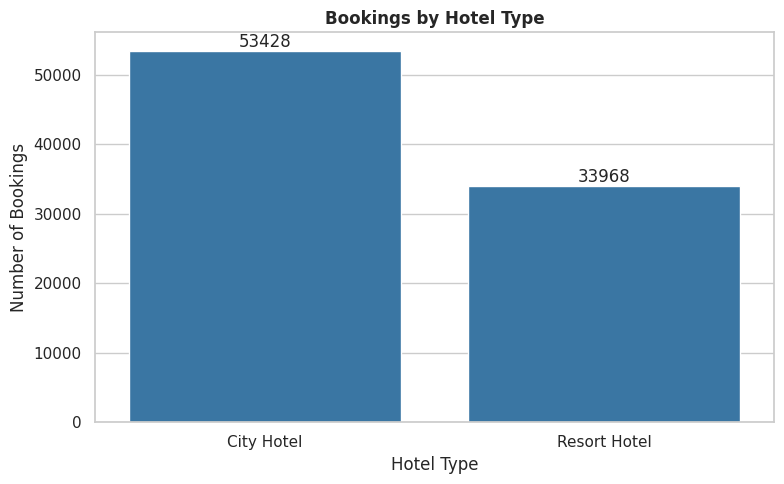

hotel
City Hotel      61.13
Resort Hotel    38.87
Name: Booking Share (%), dtype: float64

In [12]:
hotel_counts = data["hotel"].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=hotel_counts.index, y=hotel_counts.values, color="#2878B5")
plt.title("Bookings by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.tight_layout()

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.show()

(hotel_counts / len(data) * 100).round(2).rename("Booking Share (%)")

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [13]:
print("CHART INSIGHT — BOOKINGS BY HOTEL TYPE")
print(f"{hotel_counts.idxmax()} has the highest booking volume with {hotel_counts.max():,} bookings ({hotel_counts.max()/len(data)*100:.2f}% of cleaned bookings).")
print("Interpretation: booking volume shows demand share; it does not by itself prove higher profitability.")

CHART INSIGHT — BOOKINGS BY HOTEL TYPE
City Hotel has the highest booking volume with 53,428 bookings (61.13% of cleaned bookings).
Interpretation: booking volume shows demand share; it does not by itself prove higher profitability.


## **STEP 8 — BOOKING LEAD TIME DISTRIBUTION**

**Business question:** How many days in advance do guests usually book?

The histogram shows the distribution. We include both the mean and median because a small number of very long lead times can pull the mean upward.

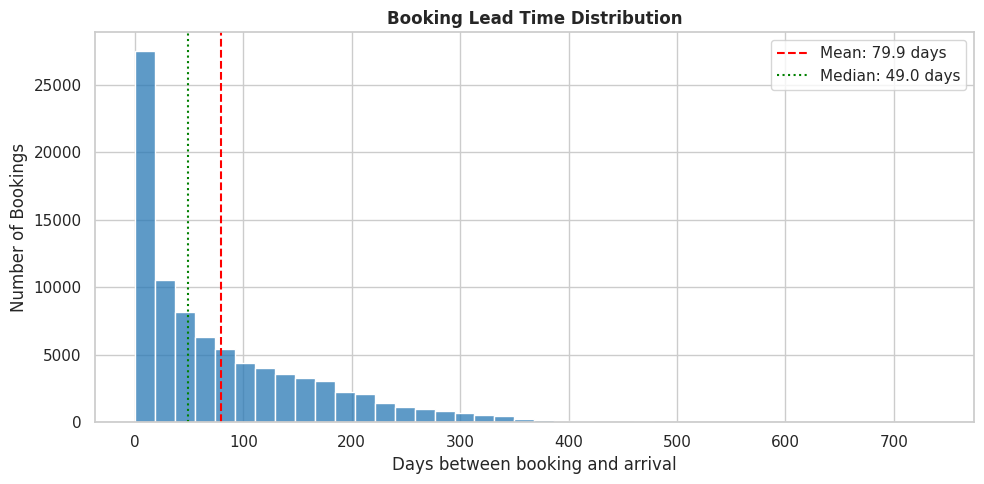

In [14]:
mean_lead = data["lead_time"].mean()
median_lead = data["lead_time"].median()

plt.figure(figsize=(10, 5))
sns.histplot(data=data, x="lead_time", bins=40, color="#2878B5")
plt.axvline(mean_lead, color="red", linestyle="--",
            label=f"Mean: {mean_lead:.1f} days")
plt.axvline(median_lead, color="green", linestyle=":",
            label=f"Median: {median_lead:.1f} days")
plt.title("Booking Lead Time Distribution")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Number of Bookings")
plt.legend()
plt.tight_layout()
plt.show()

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [15]:
print("CHART INSIGHT — BOOKING LEAD TIME")
print(f"Average lead time is {mean_lead:.1f} days, while the median is {median_lead:.1f} days.")
print("Interpretation: when the mean is higher than the median, a smaller number of bookings made far in advance may be pulling the average upward.")

CHART INSIGHT — BOOKING LEAD TIME
Average lead time is 79.9 days, while the median is 49.0 days.
Interpretation: when the mean is higher than the median, a smaller number of bookings made far in advance may be pulling the average upward.


## **STEP 9 — CANCELLATION RATE BY HOTEL TYPE**

**Business question:** Which hotel type has a higher cancellation rate?

We calculate the average of `is_canceled` for each hotel. Since the column contains 1 for canceled and 0 for not canceled, its mean gives the cancellation rate.

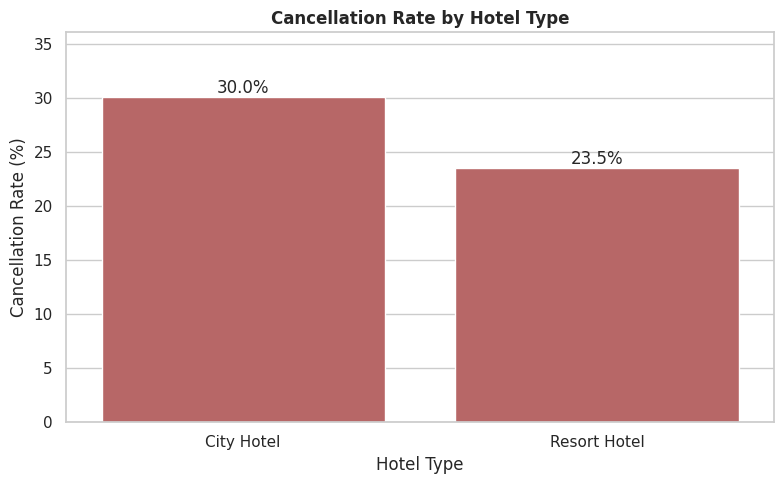

hotel
City Hotel      30.04
Resort Hotel    23.48
Name: Cancellation Rate (%), dtype: float64

In [16]:
hotel_cancel = data.groupby("hotel")["is_canceled"].mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=hotel_cancel.index, y=hotel_cancel.values, color="#C45A5A")
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, max(hotel_cancel.values) * 1.2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.show()

hotel_cancel.round(2).rename("Cancellation Rate (%)")

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [17]:
print("CHART INSIGHT — CANCELLATION RATE BY HOTEL")
print(f"{hotel_cancel.idxmax()} has the higher cancellation rate at {hotel_cancel.max():.2f}%.")
print(f"The difference between the two hotel types is {abs(hotel_cancel.iloc[0] - hotel_cancel.iloc[-1]):.2f} percentage points.")
print("Interpretation: the hotel with the higher rate may need a closer review of booking lead time, deposit type and channel mix.")

CHART INSIGHT — CANCELLATION RATE BY HOTEL
City Hotel has the higher cancellation rate at 30.04%.
The difference between the two hotel types is 6.56 percentage points.
Interpretation: the hotel with the higher rate may need a closer review of booking lead time, deposit type and channel mix.


## **STEP 10 — MONTHLY ARRIVAL PATTERN**

**Business question:** Which months have the highest number of bookings?

We order months correctly from January to December. This chart helps operations teams plan staffing and supplies around busy periods.

**Caution:** The dataset covers multiple years and the year coverage is not necessarily complete for every month. This chart counts all available records by month; it is not a year-over-year comparison.

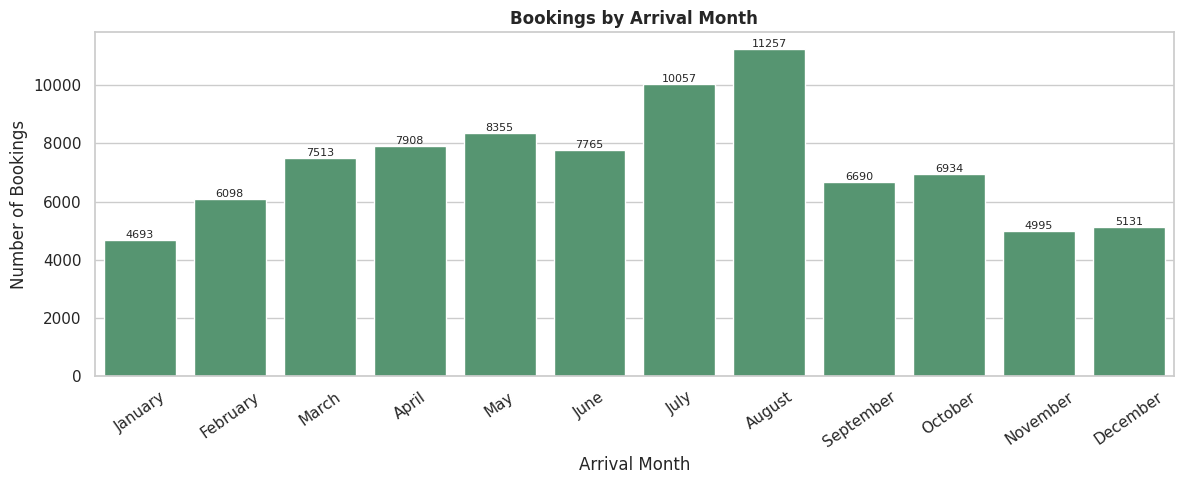

Busiest arrival month: August


In [18]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_bookings = data["arrival_date_month"].value_counts().reindex(month_order)

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=monthly_bookings.index, y=monthly_bookings.values, color="#4C9F70")
plt.title("Bookings by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=35)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8)
plt.tight_layout()
plt.show()

print("Busiest arrival month:", monthly_bookings.idxmax())

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [19]:
print("CHART INSIGHT — MONTHLY ARRIVAL BOOKINGS")
print(f"{monthly_bookings.idxmax()} has the most arrivals ({monthly_bookings.max():,.0f} bookings); {monthly_bookings.idxmin()} has the fewest ({monthly_bookings.min():,.0f}).")
print("Interpretation: this is a combined monthly total across all years in the dataset, not an average for a typical year.")

CHART INSIGHT — MONTHLY ARRIVAL BOOKINGS
August has the most arrivals (11,257 bookings); January has the fewest (4,693).
Interpretation: this is a combined monthly total across all years in the dataset, not an average for a typical year.


## **STEP 11 — MARKET SEGMENT ANALYSIS**

**Business question:** Which market segments contribute the most bookings?

Market segments help the marketing team understand how guests find or purchase hotel stays.

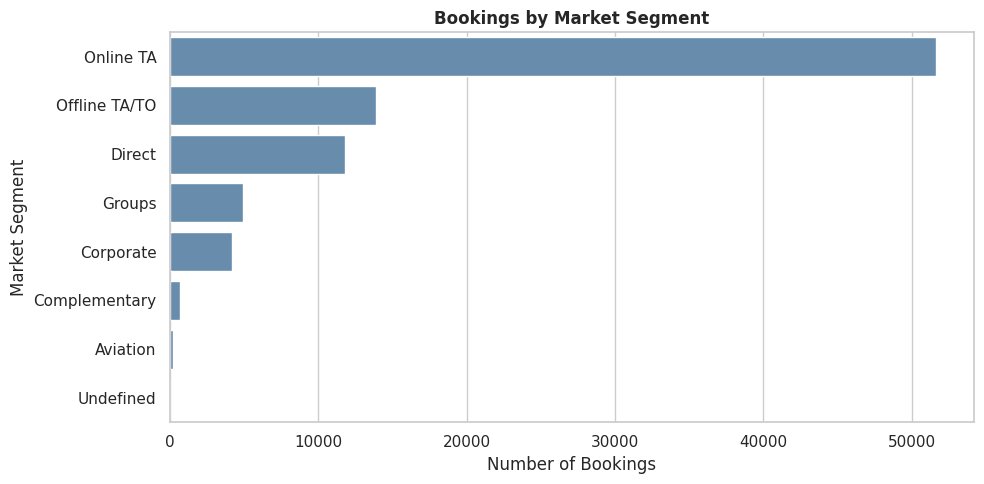

market_segment
Online TA        59.06
Offline TA/TO    15.89
Direct           13.51
Groups            5.65
Corporate         4.82
Complementary     0.80
Aviation          0.26
Undefined         0.00
Name: Booking Share (%), dtype: float64

In [20]:
segment_counts = data["market_segment"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=segment_counts.values, y=segment_counts.index, color="#5B8DB8")
plt.title("Bookings by Market Segment")
plt.xlabel("Number of Bookings")
plt.ylabel("Market Segment")
plt.tight_layout()
plt.show()

segment_share = (segment_counts / len(data) * 100).round(2)
segment_share.rename("Booking Share (%)")

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [21]:
print("CHART INSIGHT — MARKET SEGMENTS")
print(f"{segment_counts.idxmax()} is the largest segment with {segment_counts.max():,} bookings ({segment_counts.max()/len(data)*100:.2f}%).")
print("Interpretation: the largest segment is the biggest source of booking volume; compare cancellation rate and ADR before judging its value.")

CHART INSIGHT — MARKET SEGMENTS
Online TA is the largest segment with 51,618 bookings (59.06%).
Interpretation: the largest segment is the biggest source of booking volume; compare cancellation rate and ADR before judging its value.


## **STEP 12 — DISTRIBUTION CHANNEL ANALYSIS**

**Business question:** Which distribution channel brings the most bookings?

This can help the business understand the importance of direct bookings, travel agents and other channels.

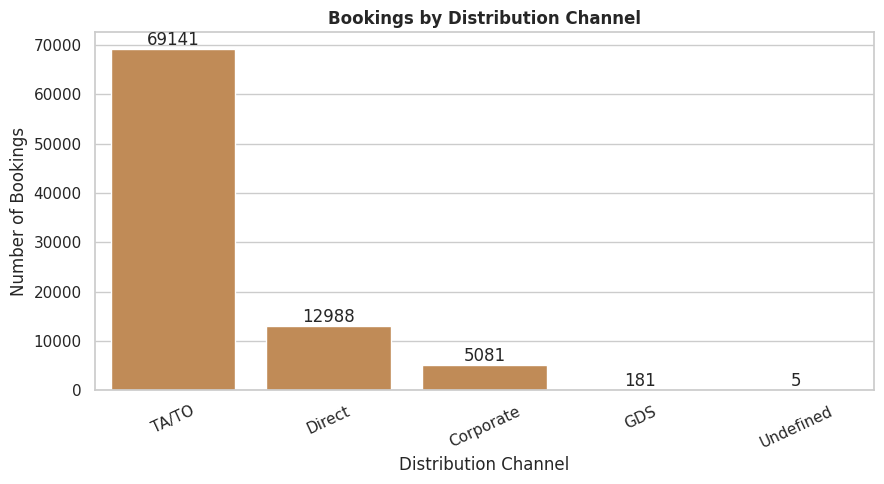

In [22]:
channel_counts = data["distribution_channel"].value_counts()

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=channel_counts.index, y=channel_counts.values, color="#D28B45")
plt.title("Bookings by Distribution Channel")
plt.xlabel("Distribution Channel")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=25)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [23]:
print("CHART INSIGHT — DISTRIBUTION CHANNELS")
print(f"{channel_counts.idxmax()} contributes the most bookings ({channel_counts.max():,}; {channel_counts.max()/len(data)*100:.2f}%).")
print("Interpretation: high booking volume identifies an important channel, but channel profitability is not measured here.")

CHART INSIGHT — DISTRIBUTION CHANNELS
TA/TO contributes the most bookings (69,141; 79.11%).
Interpretation: high booking volume identifies an important channel, but channel profitability is not measured here.


## **STEP 13 — ADR COMPARISON BY HOTEL TYPE**

**Business question:** How does the Average Daily Rate differ between City and Resort Hotels?

We exclude negative ADR values from this analysis. To keep the chart readable, we display values up to the 99th percentile. This is only a chart display filter; the underlying `adr_data` is not permanently trimmed.

ADR is a rate per night, not total booking revenue.

Average ADR by hotel type:


hotel
City Hotel      110.99
Resort Hotel     99.03
Name: adr, dtype: float64

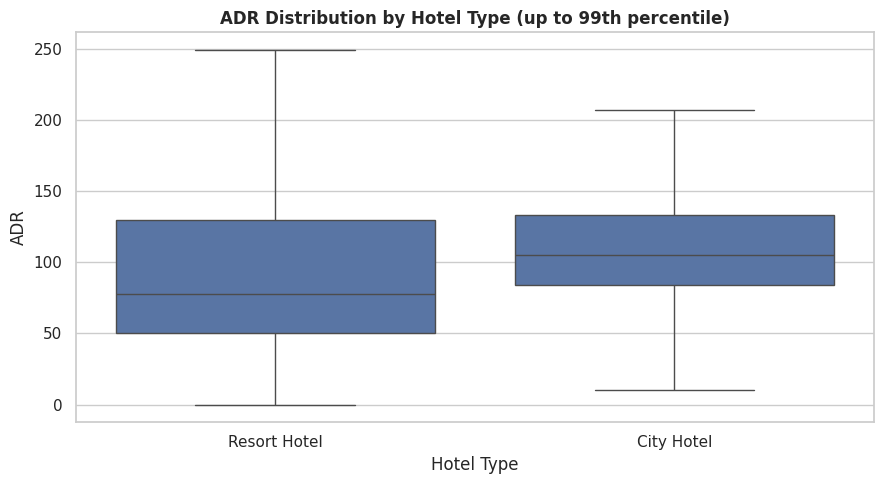

In [24]:
adr_limit = adr_data["adr"].quantile(0.99)
adr_chart = adr_data[adr_data["adr"] <= adr_limit]

adr_by_hotel = adr_data.groupby("hotel")["adr"].mean().sort_values(ascending=False)
print("Average ADR by hotel type:")
display(adr_by_hotel.round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(data=adr_chart, x="hotel", y="adr", showfliers=False)
plt.title("ADR Distribution by Hotel Type (up to 99th percentile)")
plt.xlabel("Hotel Type")
plt.ylabel("ADR")
plt.tight_layout()
plt.show()

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [25]:
print("CHART INSIGHT — ADR BY HOTEL TYPE")
print(f"{adr_by_hotel.idxmax()} has the higher average ADR ({adr_by_hotel.max():.2f}).")
print("The boxplot focuses on values up to the 99th percentile for readability; the average ADR calculation uses all non-negative ADR records.")
print("Interpretation: ADR is an average nightly rate, not total revenue or profit.")

CHART INSIGHT — ADR BY HOTEL TYPE
City Hotel has the higher average ADR (110.99).
The boxplot focuses on values up to the 99th percentile for readability; the average ADR calculation uses all non-negative ADR records.
Interpretation: ADR is an average nightly rate, not total revenue or profit.


## **STEP 14 — ADR TREND BY YEAR**

**Business question:** How does average ADR change across arrival years?

We calculate average ADR for each arrival year and hotel type. This provides a simple view of rate changes over time.

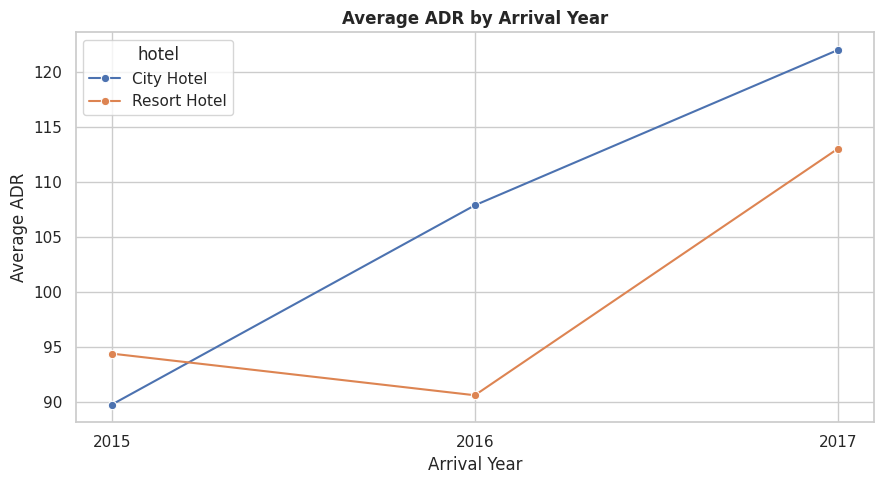

,arrival_date_year,hotel,adr
0,2015,City Hotel,89.813927
1,2015,Resort Hotel,94.433664
2,2016,City Hotel,107.896449
3,2016,Resort Hotel,90.655998
4,2017,City Hotel,121.987908
5,2017,Resort Hotel,113.023670


In [26]:
year_adr = (
    adr_data.groupby(["arrival_date_year", "hotel"])["adr"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.lineplot(data=year_adr, x="arrival_date_year", y="adr",
             hue="hotel", marker="o")
plt.title("Average ADR by Arrival Year")
plt.xlabel("Arrival Year")
plt.ylabel("Average ADR")
plt.xticks(sorted(data["arrival_date_year"].unique()))
plt.tight_layout()
plt.show()

year_adr

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [27]:
print("CHART INSIGHT — ADR BY YEAR")
for hotel_name in year_adr["hotel"].unique():
    hotel_rows = year_adr[year_adr["hotel"] == hotel_name].sort_values("arrival_date_year")
    if len(hotel_rows) >= 2:
        first_rate = hotel_rows.iloc[0]["adr"]
        last_rate = hotel_rows.iloc[-1]["adr"]
        print(f"{hotel_name}: ADR changed from {first_rate:.2f} in {int(hotel_rows.iloc[0]['arrival_date_year'])} to {last_rate:.2f} in {int(hotel_rows.iloc[-1]['arrival_date_year'])}.")
print("Interpretation: compare years carefully because the first and last years may cover only part of the year.")

CHART INSIGHT — ADR BY YEAR
City Hotel: ADR changed from 89.81 in 2015 to 121.99 in 2017.
Resort Hotel: ADR changed from 94.43 in 2015 to 113.02 in 2017.
Interpretation: compare years carefully because the first and last years may cover only part of the year.


## **STEP 15 — TOP COUNTRIES BY BOOKINGS**

**Business question:** Which countries contribute the most bookings?

We keep `"Unknown"` out of the top-country chart so the ranking shows known country names.

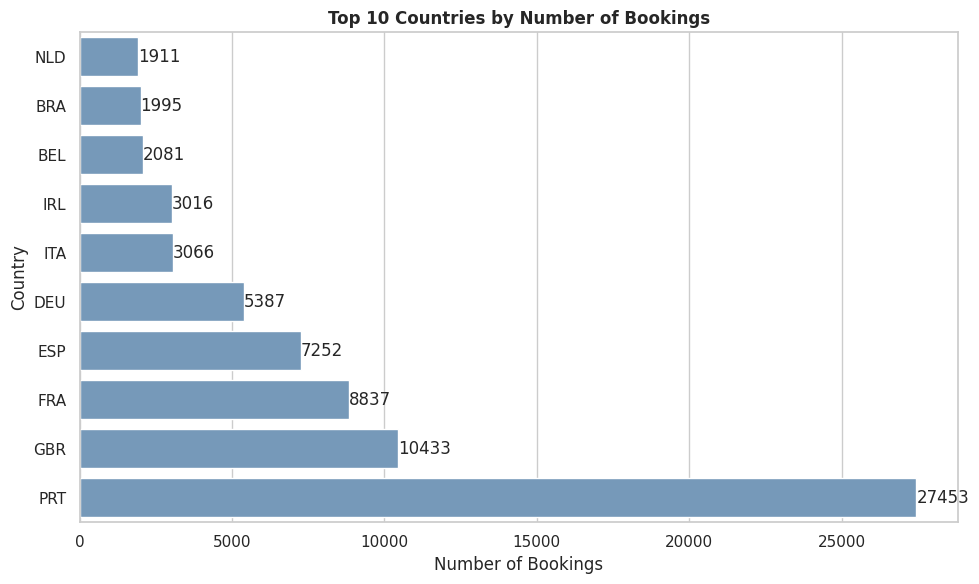

In [28]:
top_countries = (
    data[data["country"] != "Unknown"]["country"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_countries.values, y=top_countries.index, color="#6B9AC4")
plt.title("Top 10 Countries by Number of Bookings")
plt.xlabel("Number of Bookings")
plt.ylabel("Country")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [29]:
print("CHART INSIGHT — TOP COUNTRIES")
print(f"{top_countries.idxmax()} is the leading known country with {top_countries.max():,} bookings.")
print("Interpretation: country counts describe booking origin; they do not represent unique guests because one guest may make multiple bookings.")

CHART INSIGHT — TOP COUNTRIES
PRT is the leading known country with 27,453 bookings.
Interpretation: country counts describe booking origin; they do not represent unique guests because one guest may make multiple bookings.


## **STEP 16 — GUEST PREFERENCES AND SPECIAL REQUESTS**

**Business question:** How many special requests do guests make?

Special requests can indicate service needs, but they are not a direct customer satisfaction score. We should not claim that more requests automatically mean higher satisfaction.

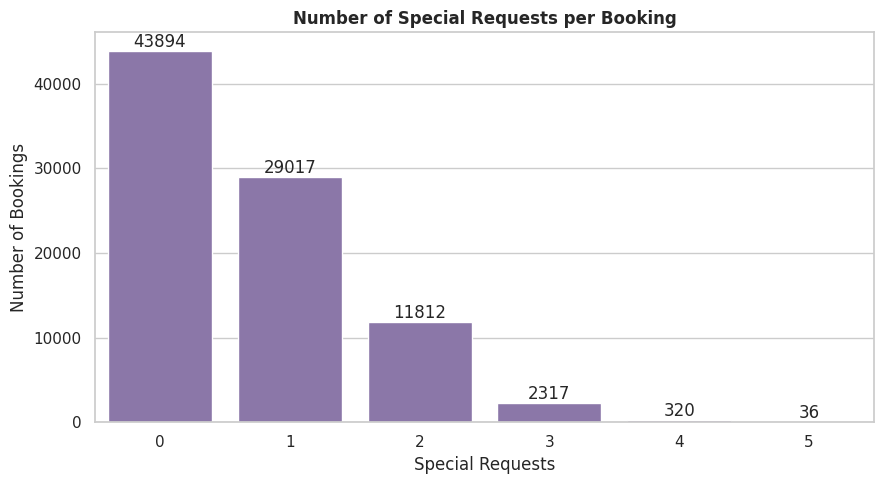

Average special requests per booking: 0.7


In [30]:
request_counts = data["total_of_special_requests"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=request_counts.index, y=request_counts.values, color="#8A6FB0")
plt.title("Number of Special Requests per Booking")
plt.xlabel("Special Requests")
plt.ylabel("Number of Bookings")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

print("Average special requests per booking:",
      round(data["total_of_special_requests"].mean(), 2))

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [31]:
print("CHART INSIGHT — SPECIAL REQUESTS")
most_common_request_count = request_counts.idxmax()
print(f"The most common number of special requests per booking is {most_common_request_count} ({request_counts.max():,} bookings).")
print(f"{(data['total_of_special_requests'] == 0).mean()*100:.2f}% of bookings have no special requests.")
print("Interpretation: special requests help with service planning but are not a direct customer-satisfaction score.")

CHART INSIGHT — SPECIAL REQUESTS
The most common number of special requests per booking is 0 (43,894 bookings).
50.22% of bookings have no special requests.
Interpretation: special requests help with service planning but are not a direct customer-satisfaction score.


## **STEP 17 — STAY DURATION BY HOTEL TYPE**

**Business question:** Do guests stay longer at City Hotels or Resort Hotels?

We compare weekday nights, weekend nights and total nights. This can support room planning and package design.

In [32]:
stay_summary = data.groupby("hotel")[
    ["stays_in_week_nights", "stays_in_weekend_nights", "total_nights"]
].mean()

stay_summary.round(2)

,stays_in_week_nights,stays_in_weekend_nights,total_nights
hotel,,,
City Hotel,2.27,0.87,3.15
Resort Hotel,3.18,1.21,4.39


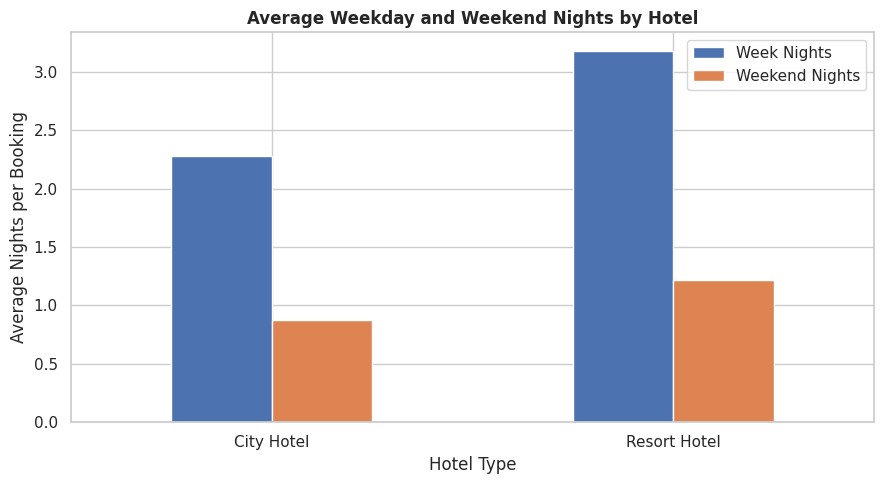

In [33]:
stay_plot = stay_summary[["stays_in_week_nights", "stays_in_weekend_nights"]]

stay_plot.plot(kind="bar", figsize=(9, 5))
plt.title("Average Weekday and Weekend Nights by Hotel")
plt.xlabel("Hotel Type")
plt.ylabel("Average Nights per Booking")
plt.xticks(rotation=0)
plt.legend(["Week Nights", "Weekend Nights"])
plt.tight_layout()
plt.show()

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [34]:
print("CHART INSIGHT — STAY DURATION BY HOTEL")
print(f"Average total nights: City Hotel = {stay_summary.loc['City Hotel', 'total_nights']:.2f}; Resort Hotel = {stay_summary.loc['Resort Hotel', 'total_nights']:.2f}.")
print("Interpretation: the hotel type with longer stays may need different housekeeping and staffing plans.")

CHART INSIGHT — STAY DURATION BY HOTEL
Average total nights: City Hotel = 3.15; Resort Hotel = 4.39.
Interpretation: the hotel type with longer stays may need different housekeeping and staffing plans.


## **STEP 18 — REPEATED GUEST ANALYSIS**

**Business question:** Do repeat guests stay for a different length of time than new guests?

We compare average total nights. This can help the hotel think about loyalty offers and retention.

In [35]:
data["guest_group"] = data["is_repeated_guest"].map({
    0: "New Guest",
    1: "Repeated Guest"
})

repeat_summary = data.groupby("guest_group").agg(
    bookings=("hotel", "size"),
    average_stay_nights=("total_nights", "mean"),
    average_special_requests=("total_of_special_requests", "mean")
).round(2)

repeat_summary

,bookings,average_stay_nights,average_special_requests
guest_group,,,
New Guest,83981,3.70,0.70
Repeated Guest,3415,1.93,0.69


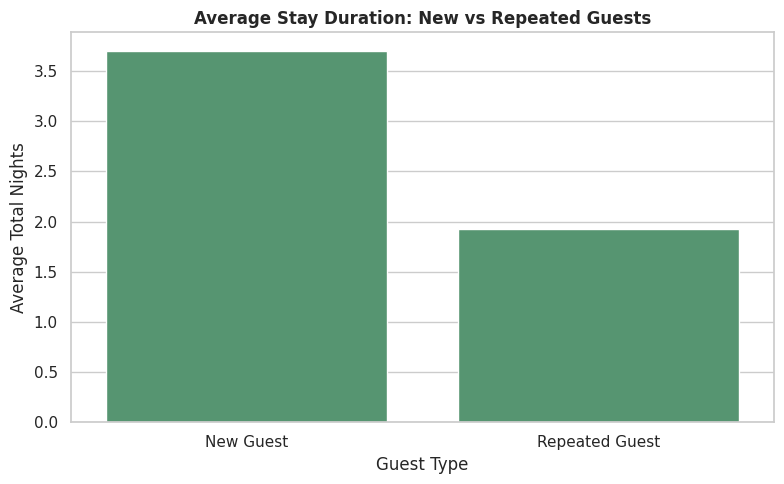

In [36]:
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x="guest_group", y="total_nights",
            estimator="mean", errorbar=None, color="#4C9F70")
plt.title("Average Stay Duration: New vs Repeated Guests")
plt.xlabel("Guest Type")
plt.ylabel("Average Total Nights")
plt.tight_layout()
plt.show()

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [37]:
print("CHART INSIGHT — REPEATED VS NEW GUESTS")
guest_stay_means = data.groupby("guest_group")["total_nights"].mean()
for guest_type, average_nights in guest_stay_means.items():
    print(f"{guest_type}: average stay = {average_nights:.2f} nights.")
print("Interpretation: this compares booking records by repeat-guest flag, not unique people across the full dataset.")

CHART INSIGHT — REPEATED VS NEW GUESTS
New Guest: average stay = 3.70 nights.
Repeated Guest: average stay = 1.93 nights.
Interpretation: this compares booking records by repeat-guest flag, not unique people across the full dataset.


## **STEP 19 — ESTIMATED LODGING REVENUE BY MONTH**

**Business question:** Which arrival months have the highest estimated lodging revenue?

For this estimate, we use only non-canceled bookings with non-negative ADR and at least one night.

**Formula:** `Estimated lodging revenue = ADR × total nights`

This is a simplified estimate based on the available fields. It does not include taxes, fees, refunds, food and beverage, or other revenue. The ADR field is defined in the data dictionary as lodging revenue divided by staying nights.

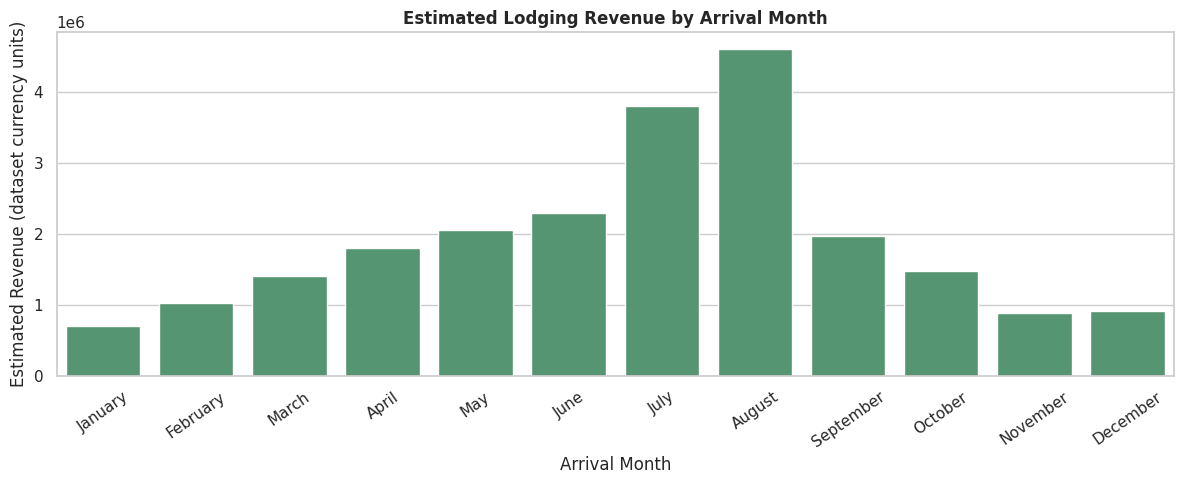

Month with highest estimated revenue: August
Completed check-out bookings used: 62,748
Total estimated lodging revenue: 22,976,960.13


In [38]:
# Use actual Check-Out records, not merely non-canceled bookings (which can include No-Show records).
completed_stays = revenue_data[revenue_data["reservation_status"] == "Check-Out"].copy()
completed_stays["estimated_lodging_revenue"] = (
    completed_stays["adr"] * completed_stays["total_nights"]
)

monthly_revenue = (
    completed_stays.groupby("arrival_date_month")["estimated_lodging_revenue"]
    .sum()
    .reindex(month_order)
)

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=monthly_revenue.index, y=monthly_revenue.values, color="#4C9F70")
plt.title("Estimated Lodging Revenue by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Estimated Revenue (dataset currency units)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("Month with highest estimated revenue:", monthly_revenue.idxmax())
print("Completed check-out bookings used:", f"{len(completed_stays):,}")
print("Total estimated lodging revenue:", f"{completed_stays['estimated_lodging_revenue'].sum():,.2f}")

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [39]:
print("CHART INSIGHT — ESTIMATED LODGING REVENUE")
print(f"{monthly_revenue.idxmax()} has the highest estimated lodging revenue ({monthly_revenue.max():,.2f} dataset currency units).")
print("Interpretation: estimate = ADR × nights for completed Check-Out bookings. It excludes taxes, fees and other services and is not audited revenue.")

CHART INSIGHT — ESTIMATED LODGING REVENUE
August has the highest estimated lodging revenue (4,608,288.90 dataset currency units).
Interpretation: estimate = ADR × nights for completed Check-Out bookings. It excludes taxes, fees and other services and is not audited revenue.


## **STEP 20 — CANCELLATION RATE BY MONTH**

**Business question:** Are cancellations more common in certain arrival months?

This can help the team plan cancellation policies and booking follow-up campaigns.

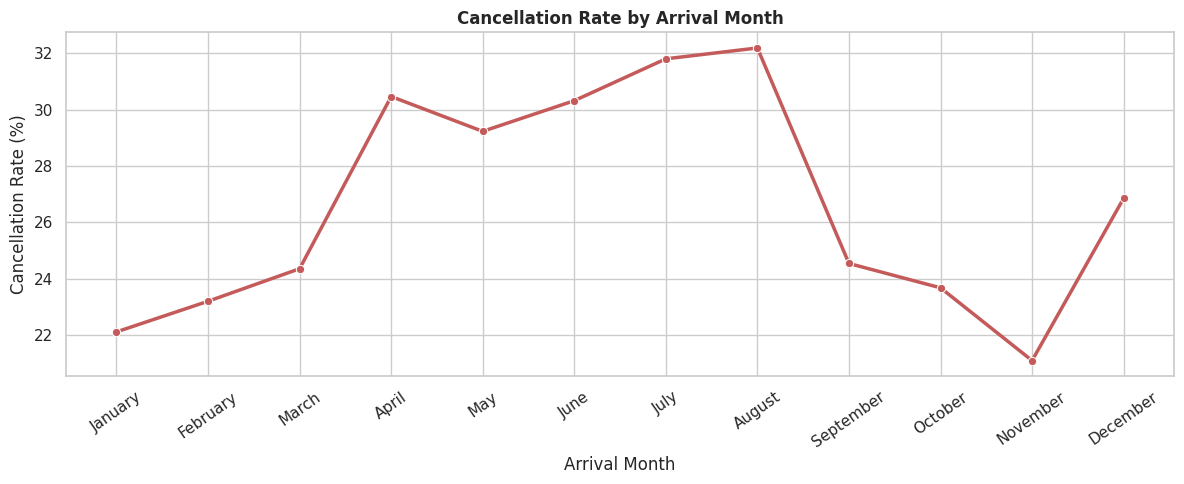

Month with highest cancellation rate: August


In [40]:
monthly_cancel = (
    data.groupby("arrival_date_month")["is_canceled"]
    .mean()
    .mul(100)
    .reindex(month_order)
)

plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_cancel.index, y=monthly_cancel.values,
             marker="o", linewidth=2.5, color="#C45A5A")
plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("Month with highest cancellation rate:", monthly_cancel.idxmax())

### **CHART INSIGHT — WHAT DOES THIS CHART TELL US?**

The next cell calculates the key takeaway directly from the dataset. These values update automatically when the notebook is rerun.


In [41]:
print("CHART INSIGHT — MONTHLY CANCELLATION RATE")
print(f"{monthly_cancel.idxmax()} has the highest monthly cancellation rate ({monthly_cancel.max():.2f}%).")
print(f"{monthly_cancel.idxmin()} has the lowest monthly cancellation rate ({monthly_cancel.min():.2f}%).")
print("Interpretation: each month's rate is canceled bookings divided by all bookings with that arrival month.")

CHART INSIGHT — MONTHLY CANCELLATION RATE
August has the highest monthly cancellation rate (32.18%).
November has the lowest monthly cancellation rate (21.10%).
Interpretation: each month's rate is canceled bookings divided by all bookings with that arrival month.


## **STEP 21 — KEY FINDINGS**

Run the cell below to create a short, data-driven summary. Read the values and explain them in your own words during an interview.

In [42]:
top_hotel = data["hotel"].value_counts().idxmax()
top_segment = data["market_segment"].value_counts().idxmax()
top_channel = data["distribution_channel"].value_counts().idxmax()
top_country = data[data["country"] != "Unknown"]["country"].value_counts().idxmax()
highest_cancel_hotel = hotel_cancel.idxmax()
highest_adr_hotel = adr_by_hotel.idxmax()

print("KEY FINDINGS")
print("-" * 55)
print(f"1. Most bookings came from: {top_hotel}")
print(f"2. Overall cancellation rate: {cancellation_rate:.2f}%")
print(f"3. Higher cancellation rate: {highest_cancel_hotel}")
print(f"4. Most common market segment: {top_segment}")
print(f"5. Leading distribution channel: {top_channel}")
print(f"6. Top known country by bookings: {top_country}")
print(f"7. Higher average ADR: {highest_adr_hotel}")
print(f"8. Busiest arrival month: {monthly_bookings.idxmax()}")
print(f"9. Highest estimated revenue month: {monthly_revenue.idxmax()}")

KEY FINDINGS
-------------------------------------------------------
1. Most bookings came from: City Hotel
2. Overall cancellation rate: 27.49%
3. Higher cancellation rate: City Hotel
4. Most common market segment: Online TA
5. Leading distribution channel: TA/TO
6. Top known country by bookings: PRT
7. Higher average ADR: City Hotel
8. Busiest arrival month: August
9. Highest estimated revenue month: August


## **STEP 22 — BUSINESS RECOMMENDATIONS**

Use the actual results from this notebook to support recommendations such as:

1. **Cancellation management:** Review cancellation patterns by hotel type, month and lead time. Consider reminders or flexible deposit options where appropriate.
2. **Seasonal planning:** Use monthly booking patterns to plan staffing, housekeeping and inventory.
3. **Marketing:** Focus campaigns on the strongest market segments and booking channels, while testing opportunities in smaller segments.
4. **Pricing:** Compare ADR by hotel type, year and month before changing room prices.
5. **Guest experience:** Use special-request patterns to prepare common services, but collect direct guest feedback before making satisfaction claims.
6. **Guest loyalty:** Compare repeat-guest behavior and consider targeted retention offers.

These are recommendations to investigate, not guaranteed outcomes. Business decisions should be tested against current hotel operations and costs.

## **STEP 23 — LIMITATIONS AND FURTHER ANALYSIS**

- The dataset does not provide room inventory, so true occupancy rate cannot be calculated.
- ADR is a rate per night; it is not the same as total booking revenue.
- Estimated lodging revenue is a simplified estimate and not audited financial data.
- Special requests are not a direct measure of customer satisfaction.
- Missing agent and company IDs are retained as missing because the reason is not fully known.
- Very high ADR values require business validation; this project does not assume every high value is incorrect.
- The dataset is historical. Current hotel decisions should use more recent data.

### Further work
- Build a cancellation prediction model after completing and validating the EDA.
- Create a Power BI dashboard for hotel managers.
- Combine booking data with room inventory and customer feedback to analyze occupancy and satisfaction more accurately.

## **STEP 24 — FINAL CONCLUSION**

This project explored hotel booking demand, guest behavior, cancellations, booking channels, room rates and estimated lodging revenue.

The analysis shows how Python can turn raw booking records into useful business information. The most important next step for a hotel team would be to investigate cancellation drivers, plan for seasonal demand and review pricing performance using validated operational data.

**Interview tip:** Be ready to explain the business question, the cleaning decision, why you selected each chart, what the chart shows and what action you recommend. Do not memorize numbers without understanding how they were calculated.

---

### Project tools
Python | Pandas | NumPy | Matplotlib | Seaborn | Jupyter Notebook